## 1. Import Library

In [1]:
#202431013_Tashfia Wahdah Fuady
import pandas as pd
import matplotlib.pyplot as plt

### 2. Membaca Dataset

In [2]:
#202431013_Tashfia Wahdah Fuady
df = pd.read_csv("fooddelivery.csv")
display(df.head())

print("Ukuran dataset:", df.shape)

,ID_Pesanan,Waktu_Transaksi,Kategori_Menu,Harga_Pesanan,Jarak_Kirim_KM,Waktu_Tunggu_Menit,Rating_Pelanggan,Ulasan_Teks,Status_Promo,Tingkat_Keluhan,Status_Pesanan
0,ORD-2024-000001,2024-03-22 13:15:14,Kopi,9000,NaN,27,4.0,Sesuai pesanan,False,Tidak Ada,Selesai
1,ORD-2024-000002,2024-01-14 17:05:37,Mie,21000,3.742238,37,NaN,NaN,False,Tidak Ada,Selesai
2,ORD-2024-000003,2024-01-04 12:32:38,Martabak,33500,12.677149,49,NaN,NaN,True,Rendah,Selesai
3,ORD-2024-000004,2024-01-26 22:34:26,Kopi,13500,2.338085,20,5.0,Mantap gan!,False,Tidak Ada,Selesai
4,ORD-2024-000005,2024-03-16 11:48:51,Ayam,47500,0.949764,27,4.0,Top bgt kualitasnya,True,Rendah,Selesai


Ukuran dataset: (8500, 11)


### 3. Menampilkan informasi dataset

In [3]:
#202431013_Tashfia Wahdah Fuady
print("Informasi dataset:")
df.info()

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Pesanan          8500 non-null   str    
 1   Waktu_Transaksi     8500 non-null   str    
 2   Kategori_Menu       8500 non-null   str    
 3   Harga_Pesanan       8500 non-null   int64  
 4   Jarak_Kirim_KM      7905 non-null   float64
 5   Waktu_Tunggu_Menit  8500 non-null   int64  
 6   Rating_Pelanggan    6800 non-null   float64
 7   Ulasan_Teks         6800 non-null   str    
 8   Status_Promo        8500 non-null   bool   
 9   Tingkat_Keluhan     8500 non-null   str    
 10  Status_Pesanan      8500 non-null   str    
dtypes: bool(1), float64(2), int64(2), str(6)
memory usage: 1.2 MB


### 4. Statistik deskriptif

In [4]:
#202431013_Tashfia Wahdah Fuady
print("Statistik deskriptif:")
display(df.describe())

Statistik deskriptif:


,Harga_Pesanan,Jarak_Kirim_KM,Waktu_Tunggu_Menit,Rating_Pelanggan
count,8.500000e+03,7905.000000,8500.000000,6800.000000
mean,1.134739e+05,3.095437,22.696941,4.175294
std,5.764418e+05,3.017151,13.488615,1.012719
min,0.000000e+00,0.500000,5.000000,1.000000
25%,1.900000e+04,0.900773,13.000000,4.000000
50%,2.900000e+04,2.141931,21.000000,4.000000
75%,4.500000e+04,4.156918,30.000000,5.000000
max,8.302000e+06,25.000000,112.000000,5.000000


### 5. Memeriksa missing value

In [5]:
#202431013_Tashfia Wahdah Fuady
print("Jumlah missing value setiap kolom:")
print(df.isna().sum())

Jumlah missing value setiap kolom:
ID_Pesanan               0
Waktu_Transaksi          0
Kategori_Menu            0
Harga_Pesanan            0
Jarak_Kirim_KM         595
Waktu_Tunggu_Menit       0
Rating_Pelanggan      1700
Ulasan_Teks           1700
Status_Promo             0
Tingkat_Keluhan          0
Status_Pesanan           0
dtype: int64


### 6. Menampilkan nilai unik atribut kategorikal

In [6]:
#202431013_Tashfia Wahdah Fuady
kolom_kategori = ["Kategori_Menu", "Status_Promo",
    "Tingkat_Keluhan", "Status_Pesanan"]

for kolom in kolom_kategori:
    print(f"\nNilai unik pada kolom {kolom}:")
    print(df[kolom].unique())


Nilai unik pada kolom Kategori_Menu:
<ArrowStringArray>
['Kopi', 'Mie', 'Martabak', 'Ayam']
Length: 4, dtype: str

Nilai unik pada kolom Status_Promo:
[False  True]

Nilai unik pada kolom Tingkat_Keluhan:
<ArrowStringArray>
['Tidak Ada', 'Rendah', 'Tinggi']
Length: 3, dtype: str

Nilai unik pada kolom Status_Pesanan:
<ArrowStringArray>
['Selesai', 'Dibatalkan', 'Refund']
Length: 3, dtype: str


### 7. Menangani missing value

In [7]:
#202431013_Tashfia Wahdah Fuady
# Kolom numerik diisi menggunakan mean
# Kolom kategorikal diisi menggunakan modus
for kolom in df.columns:
    if df[kolom].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[kolom]):
            nilai_mean = df[kolom].mean()
            df[kolom] = df[kolom].fillna(nilai_mean)
        else:
            nilai_modus = df[kolom].mode()[0]
            df[kolom] = df[kolom].fillna(nilai_modus)

print("Missing value setelah penanganan:")
print(df.isna().sum())

Missing value setelah penanganan:
ID_Pesanan            0
Waktu_Transaksi       0
Kategori_Menu         0
Harga_Pesanan         0
Jarak_Kirim_KM        0
Waktu_Tunggu_Menit    0
Rating_Pelanggan      0
Ulasan_Teks           0
Status_Promo          0
Tingkat_Keluhan       0
Status_Pesanan        0
dtype: int64


### 8. Menghitung jumlah data duplikat

In [8]:
#202431013_Tashfia Wahdah Fuady
jumlah_duplikat = df.duplicated().sum()
print("Jumlah data duplikat:", jumlah_duplikat)

Jumlah data duplikat: 0


### 9. Menghapus data duplikat

In [9]:
#202431013_Tashfia Wahdah Fuady
df = df.drop_duplicates()

print("Informasi dataset setelah menghapus duplikat:")
df.info()

Informasi dataset setelah menghapus duplikat:
<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Pesanan          8500 non-null   str    
 1   Waktu_Transaksi     8500 non-null   str    
 2   Kategori_Menu       8500 non-null   str    
 3   Harga_Pesanan       8500 non-null   int64  
 4   Jarak_Kirim_KM      8500 non-null   float64
 5   Waktu_Tunggu_Menit  8500 non-null   int64  
 6   Rating_Pelanggan    8500 non-null   float64
 7   Ulasan_Teks         8500 non-null   str    
 8   Status_Promo        8500 non-null   bool   
 9   Tingkat_Keluhan     8500 non-null   str    
 10  Status_Pesanan      8500 non-null   str    
dtypes: bool(1), float64(2), int64(2), str(6)
memory usage: 1.2 MB


### 10. Visualisasi data kategori menu

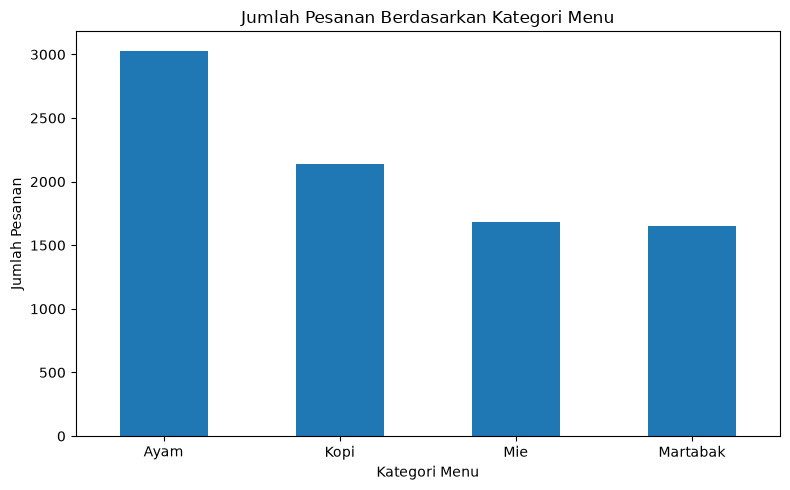

In [10]:
#202431013_Tashfia Wahdah Fuady
jumlah_menu = df["Kategori_Menu"].value_counts()

plt.figure(figsize=(8, 5))
jumlah_menu.plot(kind="bar")

plt.title("Jumlah Pesanan Berdasarkan Kategori Menu")
plt.xlabel("Kategori Menu")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()